In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.statistics import multivariate_logrank_test
from km import kaplan_meier

In [2]:
df = pd.read_parquet('../data/processed/clinical.parquet')

assert len(df) == 1979
assert (df['time'] > 0).all()

## Validating the self-written Kaplan-Meier

In [3]:
self_made = kaplan_meier(df['time'], df['event'])
kmf = KaplanMeierFitter()

own_km = pd.DataFrame(self_made, columns=['time', 'S']).drop_duplicates(subset='time', keep='last')
kmf.fit(df['time'], df['event']);

In [4]:
lifeline_values = kmf.survival_function_at_times(own_km['time'])
assert np.allclose(own_km['S'].to_numpy(), lifeline_values.to_numpy())

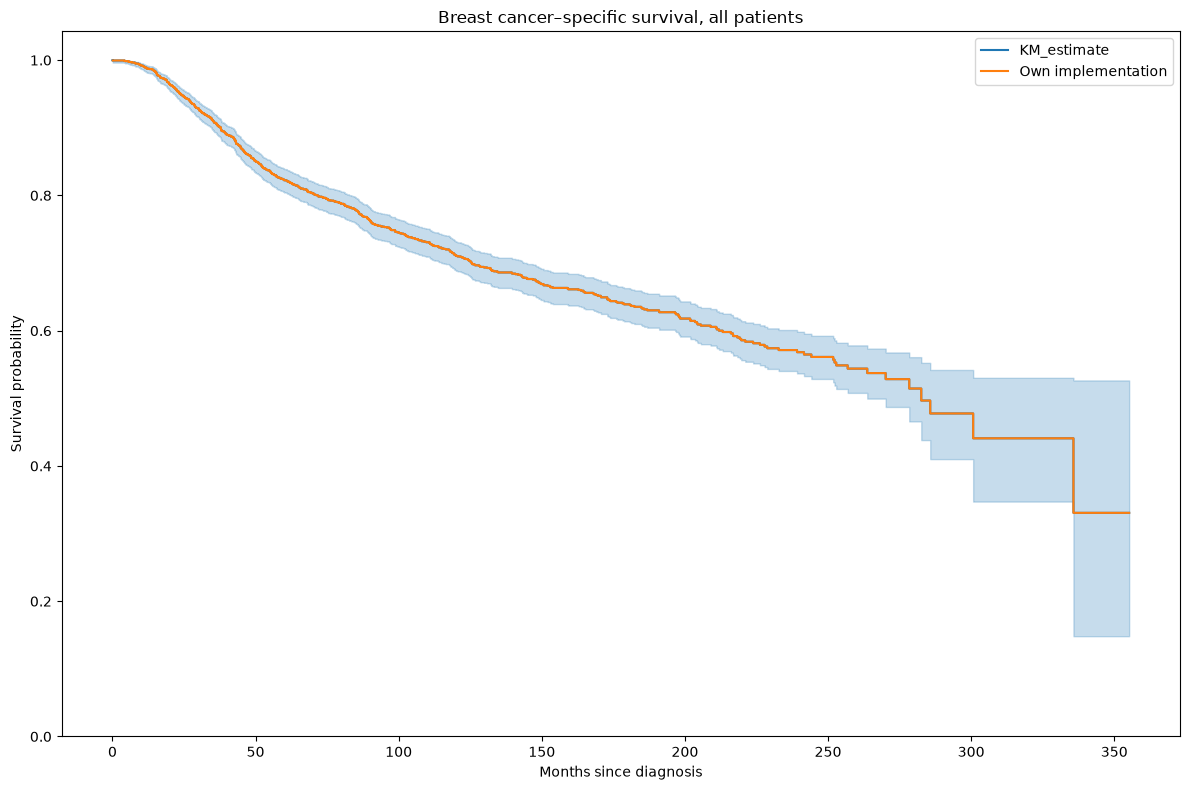

In [5]:
fig, ax = plt.subplots(figsize=(12,8))
kmf.plot(ax=ax)
ax.step(own_km['time'],own_km['S'],where='post', label='Own implementation')

ax.set_title('Breast cancer–specific survival, all patients')
ax.set_xlabel('Months since diagnosis')
ax.set_ylabel('Survival probability')
ax.set_yticks([0,0.2,0.4,0.6,0.8,1.0])


ax.legend()
plt.tight_layout()
fig.savefig('../reports/figures/kaplan_meier_graph.png', dpi=150, bbox_inches='tight')
plt.show()

### The self-written Kaplan-Meier matches lifelines exactly on all 1,979 patients.

## Survival by group

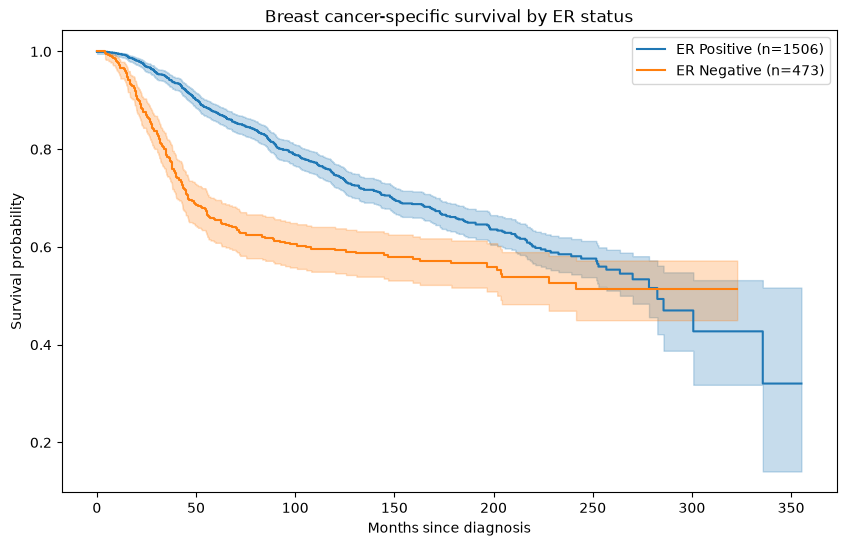

In [6]:
fig, ax = plt.subplots(figsize=(10,6))

for status in ['Positive', 'Negative']:
    group = df[df['er_status'] == status]
    kmf_group = KaplanMeierFitter()
    kmf_group.fit(group['time'], group['event'], label=f'ER {status} (n={len(group)})')
    kmf_group.plot(ax=ax)

ax.set_title('Breast cancer-specific survival by ER status')
ax.set_xlabel('Months since diagnosis')
ax.set_ylabel('Survival probability')


fig.savefig('../reports/figures/km_er_status.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
pos = df[df['er_status'] == 'Positive']
neg = df[df['er_status'] == 'Negative']

result = logrank_test(pos['time'], neg['time'], event_observed_A=pos['event'], 
                      event_observed_B=neg['event'])
print(f'Log-rank p-value: {result.p_value:.2e}')

Log-rank p-value: 1.57e-09


In [8]:
df_claudin = df.dropna(subset='claudin_subtype')

result_mvlog = multivariate_logrank_test(df_claudin['time'], df_claudin['claudin_subtype'], df_claudin['event'])

print(f'Multivariate log-rank p-value: {result_mvlog.p_value:.2e}')

Multivariate log-rank p-value: 1.18e-18


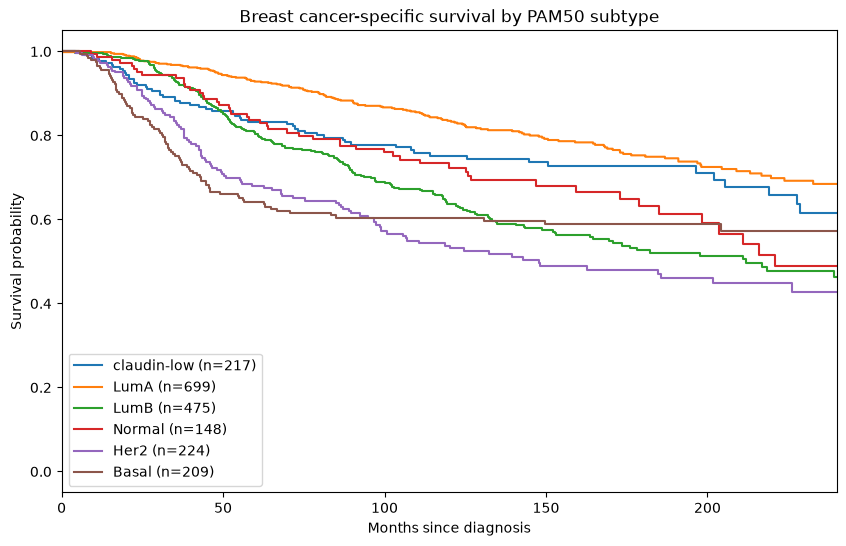

In [9]:
fig, ax = plt.subplots(figsize=(10,6))

for subtype in df_claudin['claudin_subtype'].unique():
    group = df_claudin[df_claudin['claudin_subtype'] == subtype]
    kmf_group = KaplanMeierFitter()
    kmf_group.fit(group['time'], group['event'], label=f'{subtype} (n={len(group)})')
    kmf_group.plot(ax=ax, ci_show=False)

ax.set_title('Breast cancer-specific survival by PAM50 subtype')
ax.set_xlabel('Months since diagnosis')
ax.set_ylabel('Survival probability')
ax.set_xlim(0, 240)

fig.savefig('../reports/figures/km_pam50.png', dpi=150, bbox_inches='tight')
plt.show()

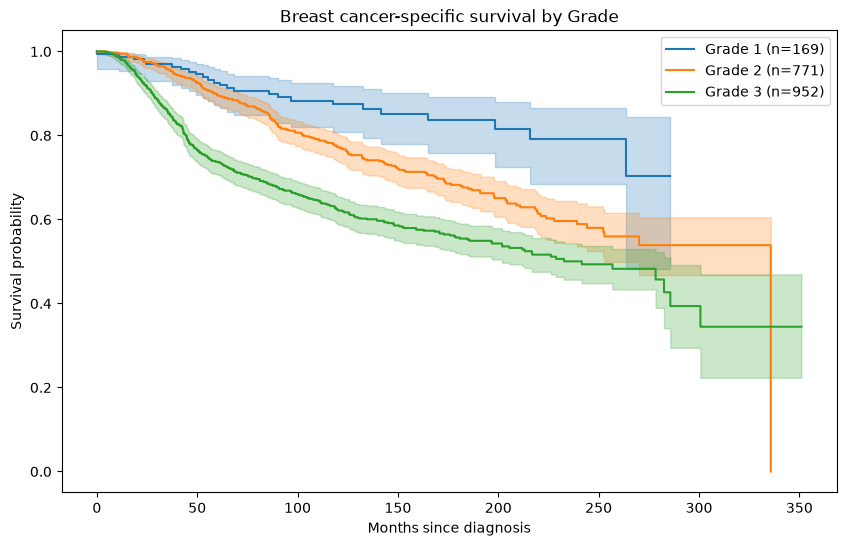

In [10]:
fig, ax = plt.subplots(figsize=(10,6))

df_grade = df.dropna(subset=['grade'])

for grade in sorted(df_grade['grade'].unique()):
    group = df_grade[df_grade['grade'] == grade]
    kmf_group = KaplanMeierFitter()
    kmf_group.fit(group['time'], group['event'], label=f'Grade {int(grade)} (n={len(group)})')
    kmf_group.plot(ax=ax)

ax.set_title('Breast cancer-specific survival by Grade')
ax.set_xlabel('Months since diagnosis')
ax.set_ylabel('Survival probability')
fig.savefig('../reports/figures/km_grade.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
result_grade = multivariate_logrank_test(df_grade['time'], df_grade['grade'], df_grade['event'])
print(f'Grade log-rank p-value: {result_grade.p_value:.2e}')

Grade log-rank p-value: 1.72e-14


### Summary

- The self-written Kaplan-Meier matches lifelines exactly on all 1,979 patients.

- ER: negative tumours die early, whereas positives keep dying for decades. Proportional hazards are violated, which matters for the Cox model.

- PAM50: **Best**: Luminal A ; **Worst**: Basal, and HER2

- Grade: 1 > 2 > 3 

- ER p-value: 1.57e-09 ; PAM50 p-value: 1.18e-18 ; Grade p-value: 1.72e-14